In [1]:
%load_ext byname

In [2]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/act_handwritten')

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [4]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    return (
        state=np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # [N, 8]
        action=np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # [N, 8]
        episode=np.asarray(
            ds.hf_dataset['episode_index'], dtype=np.int64
        ),  # [N], which demo each frame is from
    )

load_table: cached, 1 call(s) stored


In [5]:
(state=, action=, episode=) = load_table()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as bc_2 and act
is_val = np.isin(episode, val_eps)  # [N]
print(
    f'{episode.shape=} {state.shape=}  {action.shape=}',
    f'\n{val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}',
)

episode.shape=(5288,) state.shape=(5288, 8)  action.shape=(5288, 8) 
val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


In [6]:
np.random.default_rng(0).permutation(5)

array([2, 4, 3, 0, 1])

In [7]:
print(episode[:5])
print(episode[-5:])

[0 0 0 0 0]
[24 24 24 24 24]


In [8]:
def make_chunks(action: NDArray[np.float32], episode: NDArray[np.int64], K: int):
    # demo e's last row is where its run of rows ends, since demos are stored in order
    assert (np.diff(episode) >= 0).all(), 'demos not stored in order'
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(action))[:, None] + np.arange(K)  # [N, K], rows t .. t+K-1
    pad = idx > last[:, None]  # [N, K], True where the chunk runs past its demo's end
    chunks = action[
        np.minimum(idx, last[:, None])
    ]  # [N, K, 8], past the end: repeat the final action
    return (chunks=, pad=)


K = 50  # chunk length: 50 steps = 1.7 s at 30 Hz; a demo is ~210 steps
(chunks=, pad=) = make_chunks(action, episode, K)
print(f'{chunks.shape=}  {pad.shape=}')
print(f'frames whose chunk is partly padding: {pad.any(1).sum()} of {len(action)}')


chunks.shape=(5288, 50, 8)  pad.shape=(5288, 50)
frames whose chunk is partly padding: 1225 of 5288


In [9]:
last = np.searchsorted(episode, episode, side='right') - 1
last

array([ 212,  212,  212, ..., 5287, 5287, 5287], shape=(5288,))

In [10]:
print(episode[212])
print(episode[213])

0
1


In [11]:
np.arange(len(action))[:, None]

array([[   0],
       [   1],
       [   2],
       ...,
       [5285],
       [5286],
       [5287]], shape=(5288, 1))

In [12]:
print(K)
np.arange(K)

50


array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])

In [13]:
idx = np.arange(len(action))[:, None] + np.arange(K)
idx

array([[   0,    1,    2, ...,   47,   48,   49],
       [   1,    2,    3, ...,   48,   49,   50],
       [   2,    3,    4, ...,   49,   50,   51],
       ...,
       [5285, 5286, 5287, ..., 5332, 5333, 5334],
       [5286, 5287, 5288, ..., 5333, 5334, 5335],
       [5287, 5288, 5289, ..., 5334, 5335, 5336]], shape=(5288, 50))

In [14]:
pad = idx > last[:, None]
pad

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ...,  True,  True,  True],
       [False, False,  True, ...,  True,  True,  True],
       [False,  True,  True, ...,  True,  True,  True]], shape=(5288, 50))

In [15]:
np.minimum(idx, last[:, None])

array([[   0,    1,    2, ...,   47,   48,   49],
       [   1,    2,    3, ...,   48,   49,   50],
       [   2,    3,    4, ...,   49,   50,   51],
       ...,
       [5285, 5286, 5287, ..., 5287, 5287, 5287],
       [5286, 5287, 5287, ..., 5287, 5287, 5287],
       [5287, 5287, 5287, ..., 5287, 5287, 5287]], shape=(5288, 50))

In [16]:
import torch
from torch import Tensor

In [17]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as bc_2 steps 8 and 21
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item: dict[str, Tensor] = ds[i]  # this frame, decoded from both videos
        top[i] = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return (top=, wrist=)

load_images: cached, 1 call(s) stored


In [18]:
(top=, wrist=) = load_images()
print(f'{top.shape=}  {wrist.shape=}')

top.shape=(5288, 3, 128, 128)  wrist.shape=(5288, 3, 128, 128)


In [19]:
@lambda f: f()  # runs right away: a throwaway scope, so no global is touched
def probe():
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    print(len(ds))
    item: dict[str, Tensor] = ds[0]
    top_t = item['observation.images.top']
    print(top_t.shape)
    print(top_t.min(), top_t.max())
    top: NDArray = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
    print(top.min(), top.max())

5288
torch.Size([3, 128, 128])
tensor(0.) tensor(1.)
0 255


In [20]:
device = 'cuda'


def to_gpu(x: NDArray):
    # split once by episode; images stay uint8 until a batch is drawn
    return (train=torch.tensor(x[~is_val]).to(device), val=torch.tensor(x[is_val]).to(device))


def mean_std(x: Tensor, dims: tuple[int, ...]):
    # keepdim leaves a 1 for each reduced dim, so the stats broadcast straight back over x
    return (mean=x.mean(dims, keepdim=True), std=x.std(dims, keepdim=True))


data = (
    top=to_gpu(top),
    wrist=to_gpu(wrist),
    state=to_gpu(state),
    chunks=to_gpu(chunks),
    pad=to_gpu(pad),
)

# from train only, as bc_2 steps 19 and 22. Action stats from single actions: a chunk is made of
# the same actions, so they apply to every step of it
stats = (
    state=mean_std(data.state.train, (0,)),  # [1, 8] each
    action=mean_std(
        data.chunks.train[:, 0], (0,)
    ),  # [1, 8] each; chunk step 0 = that frame's action
    top=mean_std(
        data.top.train[::20].float() / 255, (0, 2, 3)
    ),  # [1, 3, 1, 1] each, every 20th frame
    wrist=mean_std(data.wrist.train[::20].float() / 255, (0, 2, 3)),
)
print(f'{data.chunks.train.shape=}\n{data.chunks.val.shape=}\n{data.pad.train.shape=}')
print('action std', stats.action.std.cpu().numpy())


data.chunks.train.shape=torch.Size([4218, 50, 8])
data.chunks.val.shape=torch.Size([1070, 50, 8])
data.pad.train.shape=torch.Size([4218, 50])
action std [[0.158 0.191 0.035 0.135 0.06  0.161 0.196 0.48 ]]


In [21]:
print(data.state.train.shape)
print(stats.state.mean.shape)

torch.Size([4218, 8])
torch.Size([1, 8])


In [22]:
print(data.chunks.train.shape)
print(data.chunks.train[:, 0].shape)
print(stats.action.mean.shape)

torch.Size([4218, 50, 8])
torch.Size([4218, 8])
torch.Size([1, 8])


In [23]:
print(data.top.train.shape)
print(stats.top.mean.shape)

torch.Size([4218, 3, 128, 128])
torch.Size([1, 3, 1, 1])


In [24]:
from torch import nn


# bc_2's image encoder, unchanged: conv stack (step 9) without its last ReLU, then spatial softmax (step 15)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    cell_x: Tensor  # buffers, declared so the checker doesn't read them as Tensor | Module
    cell_y: Tensor

    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer('cell_x', torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer('cell_y', torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)


enc = nn.Sequential(make_conv(), SpatialSoftmax(16, 16)).to(device)
x = data.top.train[:4].float() / 255  # [4, 3, 128, 128]
points: Tensor = enc((x - stats.top.mean) / stats.top.std)  # [4, 128]: 64 maps -> 64 (x, y) points
print(f'{x.shape} -> {points.shape}')


torch.Size([4, 3, 128, 128]) -> torch.Size([4, 128])


In [25]:
@lambda f: f()
def probe():
    inp = (x - stats.top.mean) / stats.top.std
    print(f'{inp.shape=}')
    conv = make_conv().to(device)
    out: Tensor = conv(inp)
    print(f'{out.shape=}')
    ss = SpatialSoftmax(16, 16).to(device)
    points: Tensor = ss(out)
    print(f'{points.shape=}')

inp.shape=torch.Size([4, 3, 128, 128])
out.shape=torch.Size([4, 64, 16, 16])
points.shape=torch.Size([4, 128])


In [26]:
class ChunkNet(nn.Module):
    # bc_2's TwoCamNet (step 23) with one change: the head outputs K actions, not 1
    def __init__(self):
        super().__init__()
        self.top = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.wrist = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.head = nn.Sequential(nn.Linear(128 * 2 + 8, 512), nn.ReLU(), nn.Linear(512, K * 8))

    def forward(self, top: Tensor, wrist: Tensor, state: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # out: [B, K, 8] radians, the next K actions
        f_top: Tensor = self.top((top - stats.top.mean) / stats.top.std)  # [B, 128]
        f_wrist: Tensor = self.wrist((wrist - stats.wrist.mean) / stats.wrist.std)  # [B, 128]
        st = (state - stats.state.mean) / stats.state.std  # [B, 8]
        out: Tensor = self.head(torch.cat([f_top, f_wrist, st], dim=-1))  # [B, 264] -> [B, K*8]
        out = out.reshape(-1, K, 8)  # [B, K, 8] in std units
        # [1, 8] stats broadcast over every chunk step
        return out * stats.action.std + stats.action.mean


net = ChunkNet().to(device)
print('params', sum(p.numel() for p in net.parameters()))
i = torch.arange(4, device=)
pred: Tensor = net(
    data.top.train[i].float() / 255,
    data.wrist.train[i].float() / 255,
    data.state.train[i],
)
print(pred.shape)  # [4, K, 8]


params 678034
torch.Size([4, 50, 8])


In [27]:
from typing import Literal


def get_batch(split: Literal['train', 'val'], i: Tensor):
    # rows i of one split, every field at once; images to floats in [0, 1] only now
    def take(x: (train: Tensor, val: Tensor)) -> Tensor:
        return (x.train if split == 'train' else x.val)[i]

    return (
        top=take(data.top).float() / 255,  # [B, 3, 128, 128]
        wrist=take(data.wrist).float() / 255,  # [B, 3, 128, 128]
        state=take(data.state),  # [B, 8]
        chunks=take(data.chunks),  # [B, K, 8]
        pad=take(data.pad),  # [B, K] bool
    )


def chunk_l1(pred: Tensor, target: Tensor, pad: Tensor) -> Tensor:
    # pred, target: [B, K, 8] radians
    # pad: [B, K] bool, True where the step is padding past the demo's end
    # out: [], mean |error| in std units (bc_2 step 20) over real steps only
    err = ((pred - target) / stats.action.std).abs()  # [B, K, 8]
    keep = (~pad)[..., None].float()  # [B, K, 1], 0 on padded steps
    return (err * keep).sum() / (keep.sum() * 8)  # divide by the number of real values, not B*K*8


torch.manual_seed(0)
b = get_batch(
    'train', torch.randint(0, len(data.state.train), (64,), device=)
)  # 64 random frames
with torch.no_grad():
    pred: Tensor = net(b.top, b.wrist, b.state)  # [64, K, 8]
print(f'padded steps in this batch: {b.pad.float().mean():.0%}')
print(f'untrained loss {chunk_l1(pred, b.chunks, b.pad):.3f}')


padded steps in this batch: 7%
untrained loss 0.798


In [28]:
print(b.pad.shape)
print(b.chunks.shape)
print(b.state.shape)
print(b.top.shape)

torch.Size([64, 50])
torch.Size([64, 50, 8])
torch.Size([64, 8])
torch.Size([64, 3, 128, 128])


In [29]:
@lambda f: f()
def probe():
    target, pad = b.chunks, b.pad
    err = ((pred - target) / stats.action.std).abs()
    print(err.shape)
    keep = (~pad)[..., None].float()
    print(keep.shape)

torch.Size([64, 50, 8])
torch.Size([64, 50, 1])


In [30]:
import torch.nn.functional as F


def random_shift(x: Tensor, shift: int = 4) -> Tensor:
    # as bc_2 step 30
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to shift px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (shift, shift, shift, shift), mode='replicate')  # [B, 3, H + 2s, W + 2s]
    dy, dx = (int(d) for d in torch.randint(0, 2 * shift + 1, (2,)))
    return x[:, :, dy : dy + H, dx : dx + W]


@torch.no_grad()
def val_error(net: nn.Module) -> Tensor:
    # out: [8], mean |error| of each chunk's FIRST action on val, radians, comparable with bc_2.
    # 256 frames at a time, never shifted
    n = len(data.state.val)
    firsts: list[Tensor] = []
    for j in range(0, n, 256):
        (top=, wrist=, state=) = get_batch(
            'val', torch.arange(j, min(j + 256, n), device=)
        )
        pred: Tensor = net(top, wrist, state)  # [<=256, K, 8]
        firsts.append(pred[:, 0])
    return (torch.cat(firsts) - data.chunks.val[:, 0]).abs().mean(0)

In [31]:
@cache
def train(
    make_net: type[nn.Module], seed: int = 0, steps: int = 3000, shift: int = 4, lr: float = 1e-3
):
    # bc_2's train() with the chunk loss; both cameras, normalised, shifted.
    # make_net: the net's class, e.g. ChunkNet; the cache keys it by name
    torch.manual_seed(seed)
    model = make_net().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=)
    err = torch.zeros(8)
    for step in range(steps + 1):
        i = torch.randint(0, len(data.state.train), (64,), device=)
        b = get_batch('train', i)
        pred: Tensor = model(
            random_shift(b.top, shift),
            random_shift(b.wrist, shift),
            b.state,
        )
        loss = chunk_l1(pred, b.chunks, b.pad)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 500 == 0:
            model.eval()  # dropout off for val, if the net has any
            err = val_error(model).cpu()
            model.train()
            print(
                f'{step:5d}  train {loss.item():.4f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}'
            )
    # weights on the CPU, so the cache holds no GPU tensors
    trained: dict[str, Tensor] = model.state_dict()
    return (weights={k: v.cpu() for k, v in trained.items()}, err=)


train: cached, 4 call(s) stored


In [32]:
(weights=, err=) = train(ChunkNet, seed=0)
net = ChunkNet().to(device)
net.load_state_dict(weights)

    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1156  val arm 0.0098  gripper 0.0810
 1000  train 0.0893  val arm 0.0078  gripper 0.0658
 1500  train 0.0678  val arm 0.0071  gripper 0.0540
 2000  train 0.0604  val arm 0.0065  gripper 0.0521
 2500  train 0.0601  val arm 0.0067  gripper 0.0454
 3000  train 0.0600  val arm 0.0061  gripper 0.0492


<All keys matched successfully>

In [33]:
import logging
import os

# render without a window; must be set before mujoco loads
os.environ.setdefault('MUJOCO_GL', 'egl')

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)

from dream_robot.core.env_api import Env
from dream_robot.core.registry import make_env
from dream_robot.core.schema import Observation

# as bc_2 steps 25-26
env: Env = make_env('robosuite/pick_place_cube')


def frame(im: np.ndarray) -> Tensor:
    # im: [H, W, 3] uint8 from the sim
    # out: [1, 3, H, W] floats in [0, 1] on the GPU
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(device).float() / 255


@torch.no_grad()
def predict(model: nn.Module, obs: Observation) -> NDArray[np.float32]:
    # model: the net to ask
    # out: [K, 8], the plan from this observation
    st = torch.from_numpy(obs.state)[None].to(device)  # [1, 8]
    chunk: Tensor = model(frame(obs.images['top']), frame(obs.images['wrist']), st)
    plan: NDArray[np.float32] = chunk[0].cpu().numpy()  # [K, 8]
    plan[:, 7] = np.clip(plan[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return plan


net.eval()
print(predict(net, env.reset(seed=1000)).shape)


(50, 8)


In [34]:
from collections import Counter

type Outcome = (success: bool, mode: str, steps: int)  # how one rollout ended


def score(results: list[Outcome]) -> str:
    # "wins/n   failures {mode: count}"
    wins = sum(r.success for r in results)
    fails = Counter(r.mode for r in results if not r.success)
    return f'{wins:2d}/{len(results)}   failures {dict(fails)}'


def rollout(model: nn.Module, seed: int, n_exec: int) -> Outcome:
    # predict a chunk, play its first n_exec actions without looking, then predict again
    obs = env.reset(seed=)
    plan: list[NDArray[np.float32]] = []  # actions still to play from the last chunk
    for step in range(600):
        if not plan:
            plan = list(predict(model, obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            return (success=r.success, mode=str(r.failure_mode), steps=step + 1)
    return (success=False, mode='no_end', steps=600)


# re-plan every 10 steps = 3 times a second
outcome = rollout(net, 1000, n_exec=10)
print(f'seed 1000: {"SUCCESS" if outcome.success else outcome.mode}  after {outcome.steps} steps')


seed 1000: SUCCESS  after 205 steps


In [35]:
@cache
def sweep(n_exec: int):
    # the same 20 unseen seeds as bc_2, each rolled out playing n_exec actions per chunk
    results = [rollout(net, seed, n_exec=) for seed in range(1000, 1020)]
    print(f'n_exec {n_exec:2d}: {score(results)}')
    return results


sweep: cached, 5 call(s) stored


In [36]:
# n_exec = 1 re-plans every step and uses only the first action, the way BC acts;
# 50 plays every chunk to its end
results = {n_exec: sweep(n_exec) for n_exec in [1, 5, 10, 25, 50]}


n_exec  1:  1/20   failures {'no_grasp': 19}
n_exec  5: 10/20   failures {'no_grasp': 10}
n_exec 10: 11/20   failures {'no_grasp': 8, 'dropped': 1}
n_exec 25: 17/20   failures {'wrong_target': 1, 'no_grasp': 1, 'dropped': 1}
n_exec 50: 14/20   failures {'no_grasp': 6}


In [37]:
from dream_robot.core.video import observation_panel

type Plan = (made: int, chunk: NDArray[np.float32])  # a chunk, and the step it was predicted at


def rollout_ensemble(
    model: nn.Module,
    seed: int,
    m: float = 0.01,
    frames: list[np.ndarray] | None = None,
) -> Outcome:
    # re-plan every step, but play the weighted average of every chunk that covers this step.
    # The chunk made at step s predicts step t as its row t - s, so up to K chunks have a say.
    # Weight exp(-m * i) with i = 0 for the OLDEST chunk (the ACT paper's choice, m = 0.01):
    # old plans count slightly more, so one jumpy new prediction can't swing the arm.
    # frames: if given, gets one [H, W, 3] panel per step: wide view + the policy's two cameras
    obs = env.reset(seed=)
    plans: list[Plan] = []  # oldest first
    for step in range(600):
        if frames is not None:
            frames.append(observation_panel(env.render(), obs.images))
        plans.append((made=step, chunk=predict(model, obs)))
        plans = [p for p in plans if step - p.made < K]  # drop chunks that ended before now
        # [n, 8], every plan's guess for now
        preds = np.stack([p.chunk[step - p.made] for p in plans])
        w = np.exp(-m * np.arange(len(preds)))  # [n], oldest first
        action: NDArray[np.float64] = (w[:, None] * preds).sum(0) / w.sum()  # [8], weighted average
        r = env.step(action)
        obs = r.observation
        if r.terminated or r.truncated:
            return (success=r.success, mode=str(r.failure_mode), steps=step + 1)
    return (success=False, mode='no_end', steps=600)


In [38]:
@cache
def ensemble(m: float):
    # the same 20 unseen seeds, ensembling with weight width m
    results = [rollout_ensemble(net, seed, m=) for seed in range(1000, 1020)]
    print(f'ensemble m={m}: {score(results)}')
    print(
        'steps of the successes:',
        sorted(r.steps for r in results if r.success),
    )
    return results


ensemble: cached, 1 call(s) stored


In [39]:
results_ens = ensemble(0.01)


ensemble m=0.01: 19/20   failures {'wrong_target': 1}
steps of the successes: [198, 202, 202, 205, 205, 205, 205, 209, 209, 211, 212, 213, 213, 213, 213, 214, 215, 219, 221]


In [40]:
@cache
def confirm_run(seed: int):
    # one training run (cached itself) under ensembling, on the same 20 seeds
    model = ChunkNet().to(device)
    model.load_state_dict(train(ChunkNet, seed=).weights)
    model.eval()
    results = [rollout_ensemble(model, s) for s in range(1000, 1020)]
    print(f'=== run {seed}: {score(results)}')
    return results


confirm_run: cached, 3 call(s) stored


In [41]:
runs = {seed: confirm_run(seed) for seed in [0, 1, 2]}
wins = [sum(r.success for r in results) for results in runs.values()]
print(f'total {sum(wins)}/60  {wins}')


    0  train 0.7986  val arm 0.1144  gripper 0.4600
  500  train 0.1156  val arm 0.0098  gripper 0.0810
 1000  train 0.0893  val arm 0.0078  gripper 0.0658
 1500  train 0.0678  val arm 0.0071  gripper 0.0540
 2000  train 0.0604  val arm 0.0065  gripper 0.0521
 2500  train 0.0601  val arm 0.0067  gripper 0.0454
 3000  train 0.0600  val arm 0.0061  gripper 0.0492
=== run 0: 19/20   failures {'wrong_target': 1}
    0  train 0.8490  val arm 0.1130  gripper 0.4590
  500  train 0.1074  val arm 0.0096  gripper 0.0739
 1000  train 0.0822  val arm 0.0075  gripper 0.0639
 1500  train 0.0718  val arm 0.0072  gripper 0.0589
 2000  train 0.0659  val arm 0.0068  gripper 0.0533
 2500  train 0.0632  val arm 0.0069  gripper 0.0506
 3000  train 0.0540  val arm 0.0060  gripper 0.0486
=== run 1: 19/20   failures {'wrong_target': 1}
    0  train 0.8460  val arm 0.1135  gripper 0.4439
  500  train 0.1033  val arm 0.0096  gripper 0.0731
 1000  train 0.0790  val arm 0.0074  gripper 0.0618
 1500  train 0.0623 

In [42]:
w = np.exp(-0.01 * np.arange(50))
w

array([1.   , 0.99 , 0.98 , 0.97 , 0.961, 0.951, 0.942, 0.932, 0.923,
       0.914, 0.905, 0.896, 0.887, 0.878, 0.869, 0.861, 0.852, 0.844,
       0.835, 0.827, 0.819, 0.811, 0.803, 0.795, 0.787, 0.779, 0.771,
       0.763, 0.756, 0.748, 0.741, 0.733, 0.726, 0.719, 0.712, 0.705,
       0.698, 0.691, 0.684, 0.677, 0.67 , 0.664, 0.657, 0.651, 0.644,
       0.638, 0.631, 0.625, 0.619, 0.613])

In [43]:
from IPython.display import Video, display

from dream_robot.core.video import write_video


def show(video: bytes) -> None:
    # embedded in the notebook, so it plays without the file
    display(Video(video, embed=True, mimetype='video/mp4', width=720))


In [44]:
@cache
def film(make_net: type[nn.Module], train_seed: int, seed: int, name: str, lr: float = 1e-3):
    # one ensembled rollout (step 12) of train(make_net, train_seed, lr=lr), filmed.
    # Cached, video bytes included: ACTNet's 600 steps don't replay bit for bit across
    # runs, so a recomputed video would differ every time
    model = make_net().to(device)
    model.load_state_dict(train(make_net, seed=train_seed, lr=).weights)
    model.eval()
    frames: list[np.ndarray] = []
    outcome = rollout_ensemble(model, seed, frames=)
    end = 'SUCCESS' if outcome.success else outcome.mode
    print(f'seed {seed}: {end} after {outcome.steps} steps')
    path = REPO / f'scratch/act_handwritten/{name}_seed{seed}.mp4'
    return (outcome=, video=write_video(frames, path, fps=env.control_hz).read_bytes())


film: cached, 2 call(s) stored


In [45]:
bad = [seed for seed, r in zip(range(1000, 1020), runs[2]) if r.mode == 'wrong_target']
print('wrong_target seeds in run 2:', bad)
show(film(ChunkNet, 2, bad[0], 'wrong_target').video)


wrong_target seeds in run 2: [1005, 1018]
    0  train 0.8460  val arm 0.1135  gripper 0.4439
  500  train 0.1033  val arm 0.0096  gripper 0.0731
 1000  train 0.0790  val arm 0.0074  gripper 0.0618
 1500  train 0.0623  val arm 0.0070  gripper 0.0534
 2000  train 0.0624  val arm 0.0068  gripper 0.0502
 2500  train 0.0548  val arm 0.0063  gripper 0.0470
 3000  train 0.0528  val arm 0.0068  gripper 0.0452
seed 1005: wrong_target after 600 steps


In [46]:
D = 256  # token width, the transformer's working size


def make_backbone() -> nn.Sequential:
    # BC's conv stack with one more stride-2 layer, so 128 px -> an 8x8 grid
    # (16x16 = 256 tokens per camera would make attention ~16x slower), then a
    # 1x1 conv that turns each cell's 128 features into one D-wide token
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 128, 3, 2, 1),  # -> [B, 128, 8, 8]
        nn.ReLU(),
        nn.Conv2d(128, D, 1),  # -> [B, D, 8, 8], one D-vector per grid cell
    )


x = data.top.train[:4].float() / 255  # [4, 3, 128, 128]
grid: Tensor = make_backbone().to(device)(x)  # [4, D, 8, 8]
tokens = grid.flatten(2).transpose(1, 2)  # [4, D, 64] -> [4, 64, D]: 64 tokens, one per cell
print(f'{grid.shape=}  ->  {tokens.shape=}')


grid.shape=torch.Size([4, 256, 8, 8])  ->  tokens.shape=torch.Size([4, 64, 256])


pos.shape=torch.Size([64, 256])


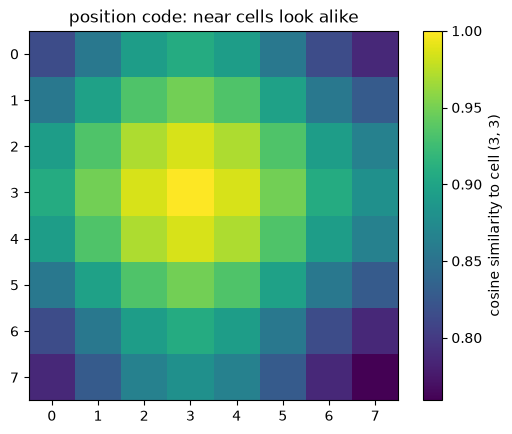

In [47]:
"""
2-D position code for an H × W grid, D numbers per cell:
    first D/2 numbers encode the row, last D/2 the column, each with the
    1-D transformer code. For position p and i = 0 … D/4 − 1:

        ωᵢ      = 10000^(−i / (D/4))                        from 1 down to ~1/10000
        code(p) = [sin(p·ω₀) … sin(p·ω_{D/4−1}),  cos(p·ω₀) … cos(p·ω_{D/4−1})]

    fast frequencies (ω ≈ 1) tell neighbouring cells apart,
    slow ones (ω ≈ 0) change smoothly across the whole grid
"""


def sinusoid_2d(h: int, w: int, d: int) -> Tensor:
    # out: [h*w, d], row-major like the flattened grid in step 15. Fixed, not learned:
    # 25 demos are too few to learn a good code for 64 cells
    q = d // 4
    omega = 10000 ** (-torch.arange(q) / q)  # [q]

    def code(n: int) -> Tensor:  # [n, d/2], the 1-D code for positions 0 .. n-1
        p = torch.arange(n)[:, None] * omega  # [n, q]
        return torch.cat([p.sin(), p.cos()], dim=-1)

    rows = code(h)[:, None, :].expand(h, w, d // 2)  # [h, w, d/2], same along a row
    cols = code(w)[None, :, :].expand(h, w, d // 2)  # [h, w, d/2], same down a column
    return torch.cat([rows, cols], dim=-1).reshape(h * w, d)


pos = sinusoid_2d(8, 8, D)  # [64, D]
print(f'{pos.shape=}')

# how alike is each cell's code to cell (row 3, col 3)'s? cosine similarity
unit = pos / pos.norm(dim=-1, keepdim=True)  # [64, D]
sim = (unit @ unit[3 * 8 + 3]).reshape(8, 8)  # [8, 8]
plt.imshow(sim, cmap='viridis')
plt.colorbar(label='cosine similarity to cell (3, 3)')
plt.title('position code: near cells look alike')
plt.show()


In [48]:
# the pieces the model will own; built loose here just to see the shapes
cam_tag = nn.Parameter(torch.randn(2, D, device=) * 0.02)  # [2, D], learned: which camera
state_in = nn.Linear(8, D).to(device)  # the 8 state numbers -> one D-wide token

# 4 frames, 4 different demos
b = get_batch('train', torch.tensor([0, 1000, 2000, 3000], device=))
cams = [  # one backbone per camera, and its tag
    (backbone=make_backbone().to(device), image=b.top, stats=stats.top, tag=cam_tag[0]),
    (backbone=make_backbone().to(device), image=b.wrist, stats=stats.wrist, tag=cam_tag[1]),
]
st: Tensor = state_in((b.state - stats.state.mean) / stats.state.std)  # [4, D]
parts = [st[:, None]]  # [4, 1, D], the state as one token
for cam in cams:
    grid: Tensor = cam.backbone((cam.image - cam.stats.mean) / cam.stats.std)  # [4, D, 8, 8]
    tok = grid.flatten(2).transpose(1, 2)  # [4, 64, D], what is in each patch
    parts.append(tok + pos.to(device) + cam.tag)  # + where it is + which camera
seq = torch.cat(parts, dim=1)  # [4, 1 + 64 + 64, D]
print([tuple(p.shape) for p in parts], '->', tuple(seq.shape))


[(4, 1, 256), (4, 64, 256), (4, 64, 256)] -> (4, 129, 256)


In [49]:
# 2 layers of: every token attends to all 129 (8 heads), then a per-token MLP of width 1024
layer = nn.TransformerEncoderLayer(
    D, nhead=8, dim_feedforward=1024,
    dropout=0.1, batch_first=True,
)
encoder = nn.TransformerEncoder(
    layer, num_layers=2,
    enable_nested_tensor=False,
).to(device)

encoder.eval()  # dropout off, so the check below sees only the mixing
with torch.no_grad():
    out: Tensor = encoder(seq)  # [4, 129, D] -> [4, 129, D], same shape
    print(f'{seq.shape=} -> {out.shape=}')

    # does information flow between tokens? change ONLY the state token (index 0)
    seq2 = seq.clone()
    seq2[:, 0] += 1.0
    out2: Tensor = encoder(seq2)
    before = (seq2 - seq)[:, 1:].abs().mean()  # the 128 image tokens, going in
    after = (out2 - out)[:, 1:].abs().mean()  # the same tokens, coming out
    print(f'image tokens changed by: {before:.3f} going in, {after:.3f} coming out')


seq.shape=torch.Size([4, 129, 256]) -> out.shape=torch.Size([4, 129, 256])
image tokens changed by: 0.000 going in, 0.006 coming out


In [50]:
# one learned vector per chunk step, asking "what should action k be?". Each looks at the
# other queries, then at all 129 encoder tokens. ACT meant 7 decoder layers but a bug
# ran only 1, and 1 worked, so 1 here
queries = nn.Parameter(torch.randn(K, D, device=) * 0.02)  # [K, D]
dlayer = nn.TransformerDecoderLayer(
    D, nhead=8, dim_feedforward=1024,
    dropout=0.1, batch_first=True,
)
decoder = nn.TransformerDecoder(dlayer, num_layers=1).to(device)
action_out = nn.Linear(D, 8).to(device)  # each query's D numbers -> one normalised action

decoder.eval()
with torch.no_grad():
    h: Tensor = decoder(
        queries.expand(len(out), K, D), out
    )  # [4, K, D], out = step 18's encoder output
    chunk: Tensor = action_out(h)  # [4, K, 8]
    print(f'{out.shape=} -> {h.shape=} -> {chunk.shape=}')

    # does the chunk depend on the observation? feed frame 1's tokens in place of frame 0's
    other: Tensor = action_out(decoder(queries.expand(1, K, D), out[1:2]))  # [1, K, 8]
    print(f'chunk change when the observation changes: {(other[0] - chunk[0]).abs().mean():.3f}')


out.shape=torch.Size([4, 129, 256]) -> h.shape=torch.Size([4, 50, 256]) -> chunk.shape=torch.Size([4, 50, 8])


chunk change when the observation changes: 0.004


In [51]:
class ACTNet(nn.Module):
    # steps 15-19 in one module. Same call and output as ChunkNet (step 6), so predict() and
    # the rollouts take it unchanged. No CVAE yet: that's ACT's other half
    pos: Tensor  # buffer, declared so the checker doesn't read it as Tensor | Module

    def __init__(self, enc_layers: int = 2, dec_layers: int = 1):
        super().__init__()
        self.top = make_backbone()
        self.wrist = make_backbone()
        self.cam_tag = nn.Parameter(torch.randn(2, D) * 0.02)  # [2, D]: top, wrist
        self.state_in = nn.Linear(8, D)
        self.register_buffer('pos', sinusoid_2d(8, 8, D))  # [64, D], moves to the GPU with the net
        enc = nn.TransformerEncoderLayer(D, 8, 1024, 0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(enc, enc_layers, enable_nested_tensor=False)
        self.queries = nn.Parameter(torch.randn(K, D) * 0.02)  # [K, D]
        dec = nn.TransformerDecoderLayer(D, 8, 1024, 0.1, batch_first=True)
        self.decoder = nn.TransformerDecoder(dec, dec_layers)
        self.action_out = nn.Linear(D, 8)

    def forward(
        self, top: Tensor, wrist: Tensor, state: Tensor, extra: Tensor | None = None
    ) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # extra: [B, n, D] more tokens to put in front (the CVAE's z, later), or None
        # out: [B, K, 8] radians, the next K actions
        st: Tensor = self.state_in((state - stats.state.mean) / stats.state.std)  # [B, D]
        parts = [] if extra is None else [extra]
        parts.append(st[:, None])  # [B, 1, D]
        cams = [
            (backbone=self.top, image=top, stats=stats.top, tag=self.cam_tag[0]),
            (backbone=self.wrist, image=wrist, stats=stats.wrist, tag=self.cam_tag[1]),
        ]
        for cam in cams:
            grid: Tensor = cam.backbone(
                (cam.image - cam.stats.mean) / cam.stats.std
            )  # [B, D, 8, 8]
            parts.append(grid.flatten(2).transpose(1, 2) + self.pos + cam.tag)  # [B, 64, D]
        mem: Tensor = self.encoder(torch.cat(parts, dim=1))  # [B, 129 (+ n), D]
        h: Tensor = self.decoder(self.queries.expand(len(state), K, D), mem)  # [B, K, D]
        out: Tensor = self.action_out(h)  # [B, K, 8] in std units
        return out * stats.action.std + stats.action.mean  # radians


act = ACTNet().to(device)
print('params', sum(p.numel() for p in act.parameters()), '  (ChunkNet, step 6: 678034)')
pred: Tensor = act(b.top, b.wrist, b.state)  # b: step 17's 4 frames
print(pred.shape)


params 3201416   (ChunkNet, step 6: 678034)
torch.Size([4, 50, 8])


In [52]:
@cache
def act_run(seed: int):
    # one ACTNet training run under ensembling, on the same 20 seeds as ChunkNet
    model = ACTNet().to(device)
    # step 8's train(); lr 1e-4, not 1e-3: transformers at 1e-3 tend to diverge
    model.load_state_dict(train(ACTNet, seed=, lr=1e-4).weights)
    model.eval()
    results = [rollout_ensemble(model, s) for s in range(1000, 1020)]
    print(f'ACTNet run {seed}: {score(results)}')
    return results


act_run: cached, 1 call(s) stored


In [53]:
act_results = act_run(0)


    0  train 0.8897  val arm 0.1144  gripper 0.4113
  500  train 0.1452  val arm 0.0143  gripper 0.0873
 1000  train 0.1165  val arm 0.0115  gripper 0.0725
 1500  train 0.1019  val arm 0.0111  gripper 0.0561
 2000  train 0.0864  val arm 0.0097  gripper 0.0469
 2500  train 0.0785  val arm 0.0092  gripper 0.0367
 3000  train 0.0761  val arm 0.0094  gripper 0.0289
ACTNet run 0: 12/20   failures {'no_grasp': 8}


In [54]:
# ACTNet's first failure, filmed like ChunkNet's wrong_target above
bad = [seed for seed, r in zip(range(1000, 1020), act_results) if not r.success]
print('failed seeds in ACTNet run 0:', bad)
show(film(ACTNet, 0, bad[0], 'actnet_fail', lr=1e-4).video)


failed seeds in ACTNet run 0: [1000, 1001, 1002, 1007, 1008, 1015, 1017, 1018]
    0  train 0.8897  val arm 0.1144  gripper 0.4113
  500  train 0.1452  val arm 0.0143  gripper 0.0873
 1000  train 0.1165  val arm 0.0115  gripper 0.0725
 1500  train 0.1019  val arm 0.0111  gripper 0.0561
 2000  train 0.0864  val arm 0.0097  gripper 0.0469
 2500  train 0.0785  val arm 0.0092  gripper 0.0367
 3000  train 0.0761  val arm 0.0094  gripper 0.0289
seed 1000: no_grasp after 600 steps
